<a href="https://colab.research.google.com/github/longyoujun/115-1/blob/main/PyTorch_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ===== VGG16 遷移學習：PyTorch + Oxford-IIIT Pet =====
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 1. 資料：一行下載，binary-category → 0 = Cat、1 = Dog（用 ImageNet 的平均值與標準差正規化）
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([transforms.Resize((256, 256)), transforms.RandomCrop(224),
                               transforms.RandomHorizontalFlip(), transforms.ToTensor(),
                               transforms.Normalize(mean, std)])
test_tf = transforms.Compose([transforms.Resize((256, 256)), transforms.CenterCrop(224),
                              transforms.ToTensor(), transforms.Normalize(mean, std)])
train_ds = datasets.OxfordIIITPet('./data', split='trainval', target_types='binary-category',
                                  transform=train_tf, download=True)
test_ds = datasets.OxfordIIITPet('./data', split='test', target_types='binary-category',
                                 transform=test_tf, download=True)
print(train_ds.bin_classes, len(train_ds), len(test_ds))
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

# 2. 訓練與測試函式
def count(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))

def fit(model, optimizer, epochs):
    criterion = nn.BCEWithLogitsLoss()      # 內含 sigmoid
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.float().unsqueeze(1).to(device)
            loss = criterion(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval(); correct = 0
        with torch.no_grad():
            for x, y in test_loader:
                pred = (model(x.to(device)) > 0).long().squeeze(1).cpu()
                correct += (pred == y).sum().item()
        print(f'epoch {epoch+1}: loss {loss.item():.4f}, test acc {correct/len(test_ds):.3f}')

# 3. 載入 ImageNet 預訓練的 VGG16，凍結 13 層卷積
model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
for p in model.features.parameters():
    p.requires_grad = False
# 4. 換上新的貓狗分類頭：全域平均池化 7×7×512 → 512 → 1
model.avgpool = nn.AdaptiveAvgPool2d(1)
model.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(512, 1))
model = model.to(device)
print('參數量 / 可訓練:', count(model))

params = [p for p in model.parameters() if p.requires_grad]
fit(model, torch.optim.SGD(params, lr=1e-3, momentum=0.9), epochs=5)

# 5.（選做）解凍 Block 5（features[24:] = conv5_1～conv5_3），用更小的學習率微調
for p in model.features[24:].parameters():
    p.requires_grad = True
print('微調時 參數量 / 可訓練:', count(model))
params = [p for p in model.parameters() if p.requires_grad]
fit(model, torch.optim.SGD(params, lr=1e-4, momentum=0.9), epochs=3)

['Cat', 'Dog'] 3680 3669
參數量 / 可訓練: (14715201, 513)
epoch 1: loss 0.1868, test acc 0.985
epoch 2: loss 0.0801, test acc 0.988
epoch 3: loss 0.1217, test acc 0.990
epoch 4: loss 0.0854, test acc 0.991
epoch 5: loss 0.1039, test acc 0.990
微調時 參數量 / 可訓練: (14715201, 7079937)
epoch 1: loss 0.1438, test acc 0.991
epoch 2: loss 0.0120, test acc 0.992
epoch 3: loss 0.0572, test acc 0.992


PyTorch: 2.11.0+cu130 | device: cuda | Tesla T4
訓練：貓  1009 張、狗  2119 張，共 3128 張
驗證：貓   179 張、狗   373 張，共 552 張
測試：貓  1183 張、狗  2486 張，共 3669 張
提醒：37 個品種中只有 12 種是貓，資料「狗多貓少」；全部猜狗在測試集就有 67.8% 準確率。


/tmp/ipykernel_981/1326866276.py:146: UserWarning: Glyph 35347 (\N{CJK UNIFIED IDEOGRAPH-8A13}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:146: UserWarning: Glyph 32244 (\N{CJK UNIFIED IDEOGRAPH-7DF4}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:146: UserWarning: Glyph 36039 (\N{CJK UNIFIED IDEOGRAPH-8CC7}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:146: UserWarning: Glyph 26009 (\N{CJK UNIFIED IDEOGRAPH-6599}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:146: UserWarning: Glyph 31684 (\N{CJK UNIFIED IDEOGRAPH-7BC4}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:146: Us

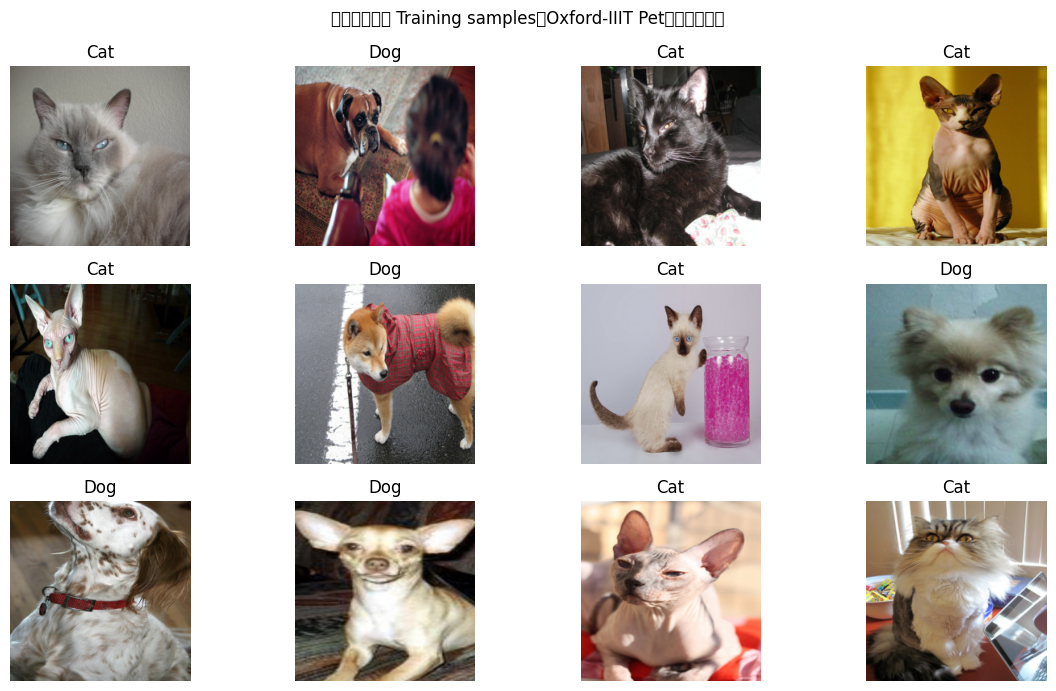

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 26550 (\N{CJK UNIFIED IDEOGRAPH-67B6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 27083 (\N{CJK UNIFIED IDEOGRAPH-69CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 38542 (\N{CJK UNIFIED IDEOGRAPH-968E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: Us

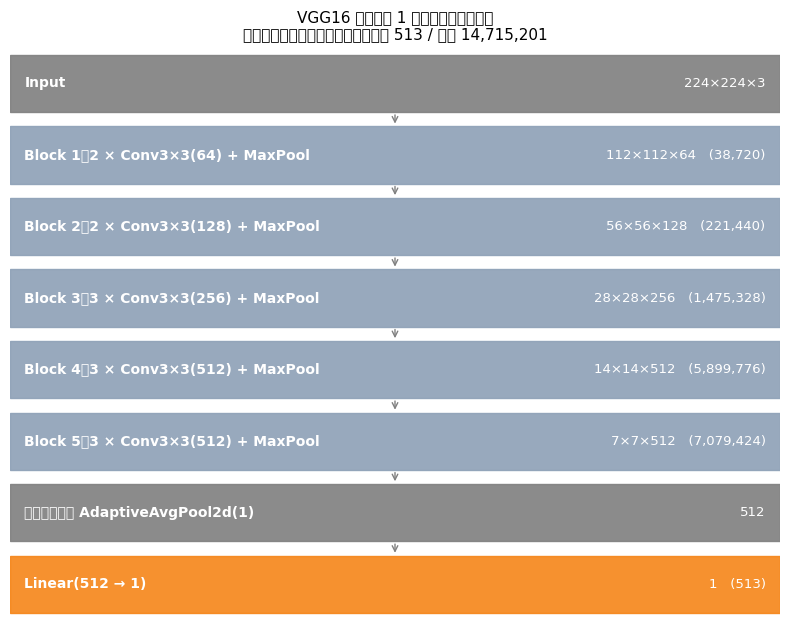


===== 第1階段：只訓練分類頭：可訓練參數 513，lr = 0.001 =====
epoch  1/5 | train loss 0.2547 acc 0.845 | val loss 0.1154 acc 0.978 | 21s  ← 最佳，已存檔
epoch  2/5 | train loss 0.1211 acc 0.955 | val loss 0.0787 acc 0.989 | 22s  ← 最佳，已存檔
epoch  3/5 | train loss 0.0952 acc 0.965 | val loss 0.0634 acc 0.989 | 22s
epoch  4/5 | train loss 0.0811 acc 0.970 | val loss 0.0547 acc 0.989 | 21s
epoch  5/5 | train loss 0.0712 acc 0.974 | val loss 0.0486 acc 0.989 | 21s


/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 24494 (\N{CJK UNIFIED IDEOGRAPH-5FAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:226: UserWarning: Glyph 35519 (\N{CJK UNIFIED IDEOGRAPH-8ABF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24494 (\N{CJK UNIFIED IDEOGRAPH-5FAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35519 (\N{CJK UNIFIED IDEOGRAPH-8ABF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


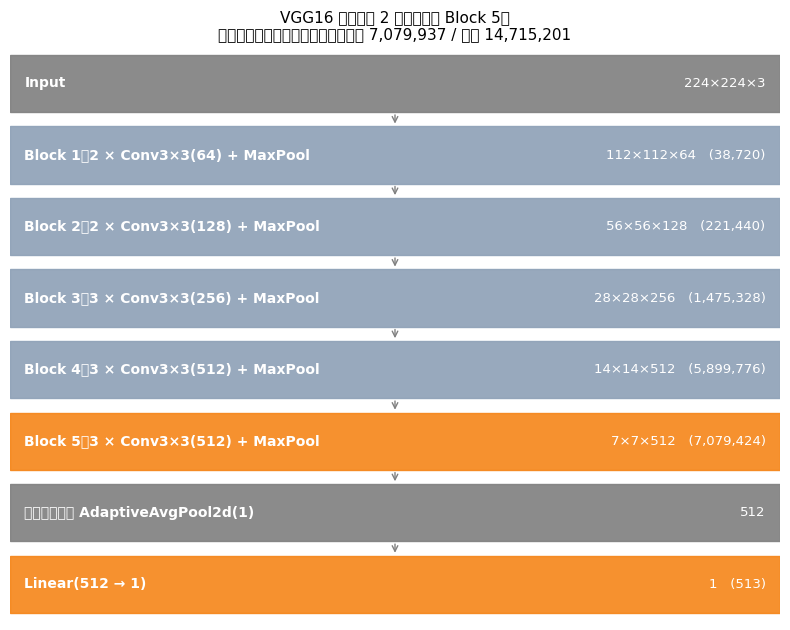


===== 第2階段：微調 Block 5：可訓練參數 7,079,937，lr = 0.0001 =====
epoch  1/5 | train loss 0.0608 acc 0.976 | val loss 0.0389 acc 0.991 | 22s  ← 最佳，已存檔
epoch  2/5 | train loss 0.0534 acc 0.978 | val loss 0.0322 acc 0.996 | 22s  ← 最佳，已存檔
epoch  3/5 | train loss 0.0465 acc 0.979 | val loss 0.0283 acc 0.995 | 22s
epoch  4/5 | train loss 0.0445 acc 0.979 | val loss 0.0255 acc 0.995 | 22s
epoch  5/5 | train loss 0.0429 acc 0.980 | val loss 0.0231 acc 0.996 | 22s


/tmp/ipykernel_981/1326866276.py:310: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:310: UserWarning: Glyph 30906 (\N{CJK UNIFIED IDEOGRAPH-78BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:310: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:310: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:310: UserWarning: Glyph 20339 (\N{CJK UNIFIED IDEOGRAPH-4F73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:310: Us

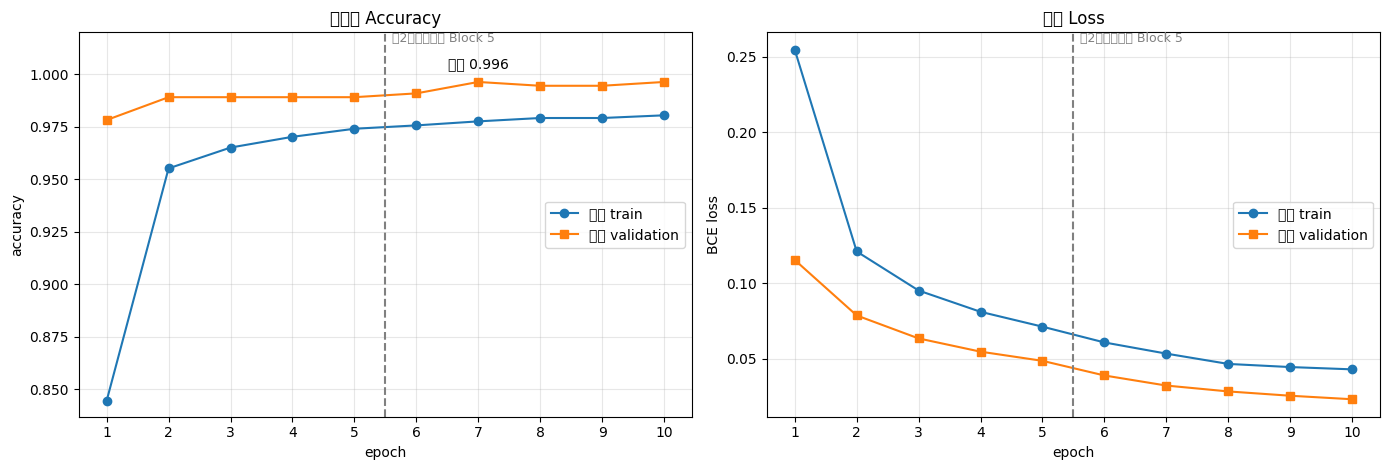

最佳驗證準確率：0.996（第 7 個 epoch，第2階段：微調 Block 5）
測試集：loss = 0.0319，準確率 = 0.9918


/tmp/ipykernel_981/1326866276.py:323: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:323: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:323: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:323: UserWarning: Glyph 23526 (\N{CJK UNIFIED IDEOGRAPH-5BE6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:323: UserWarning: Glyph 28151 (\N{CJK UNIFIED IDEOGRAPH-6DF7}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:323: Us

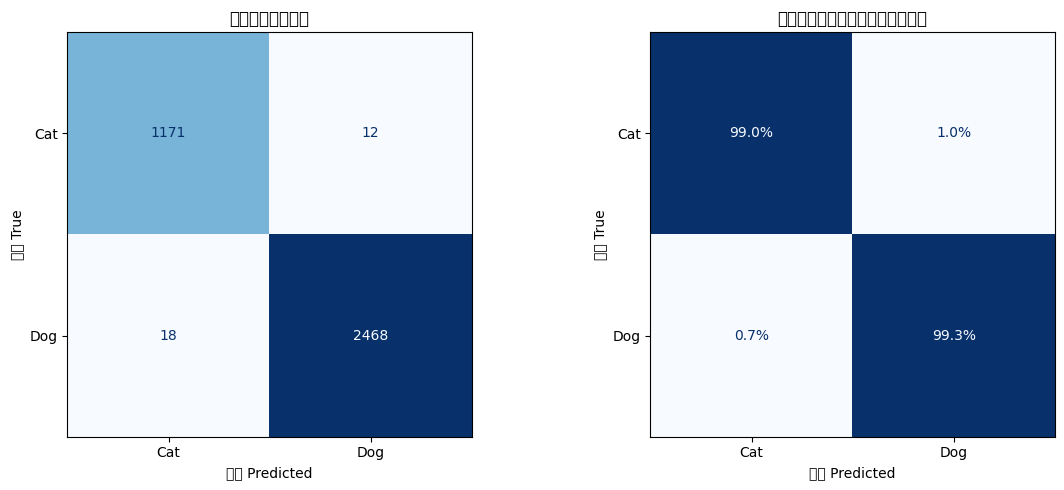

貓→貓：1171　貓→誤判為狗：12　狗→誤判為貓：18　狗→狗：2468
              precision    recall  f1-score   support

         Cat      0.985     0.990     0.987      1183
         Dog      0.995     0.993     0.994      2486

    accuracy                          0.992      3669
   macro avg      0.990     0.991     0.991      3669
weighted avg      0.992     0.992     0.992      3669



/tmp/ipykernel_981/1326866276.py:340: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:340: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:340: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:340: UserWarning: Glyph 35430 (\N{CJK UNIFIED IDEOGRAPH-8A66}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:340: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
/tmp/ipykernel_981/1326866276.py:340: Us

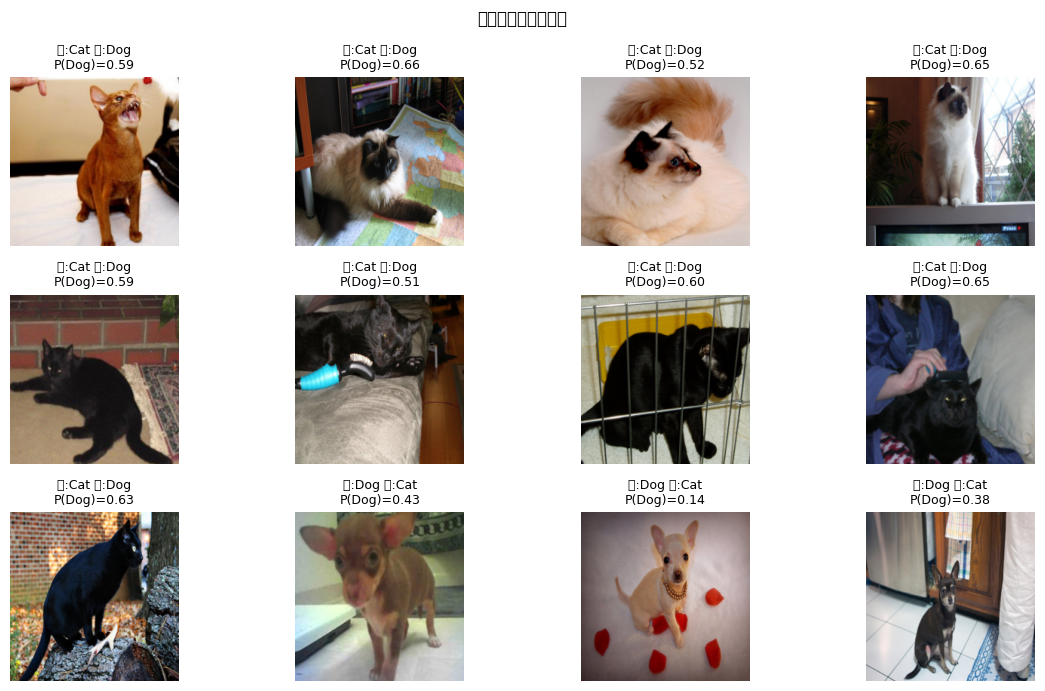


完成！圖檔與模型權重已存在目前資料夾。


In [6]:
"""
VGG16 貓狗二元分類（PyTorch／本地 Python 版）
資料集：Oxford-IIIT Pet（torchvision 內建，target_types='binary-category' → 0 = Cat、1 = Dog）

預設：遷移學習（ImageNet 預訓練 VGG16）
  第 1 階段：凍結 13 層卷積，只訓練新分類頭（513 個參數）
  第 2 階段：解凍 Block 5，用更小的學習率微調
功能：下載資料 → 建立 VGG16 → 顯示模型架構 → SGD 訓練 → 繪製準確率/損失曲線 → 測試集混淆矩陣 → 分錯的圖片

安裝套件（有 NVIDIA GPU 請依 https://pytorch.org 的指示安裝對應 CUDA 版本的 torch）：
    pip install torch torchvision scikit-learn matplotlib

執行：
    python vgg16_pet.py                          # 遷移學習：5 + 5 個 epoch
    python vgg16_pet.py --head-epochs 2 --ft-epochs 0   # 快速試跑
    python vgg16_pet.py --scratch --epochs 30    # 從頭訓練（比較用，非常慢）
    python vgg16_pet.py --no-show                # 只存圖檔、不跳出視窗
    python vgg16_pet.py --workers 0              # 若 DataLoader 在 Windows 出錯，改成 0

輸出（存在執行的資料夾）：
    samples.png、vgg16_architecture.png、vgg16_architecture_finetune.png、training_curves.png、
    confusion_matrix.png、misclassified.png、vgg16_pet_best.pt
第一次執行會下載資料集（約 800 MB，存到 ./data）與 VGG16 權重（約 528 MB）。
注意：VGG16 在 CPU 上很慢，沒有 NVIDIA GPU 建議改用 Colab 版。
"""
import argparse
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def set_chinese_font():
    """設定中文字型（Windows：微軟正黑體；macOS：蘋方；Linux：Noto Sans CJK）"""
    import matplotlib, matplotlib.font_manager as fm
    names = {f.name for f in fm.fontManager.ttflist}
    for f in ['Microsoft JhengHei', 'PingFang TC', 'Heiti TC', 'Noto Sans CJK TC', 'Noto Sans CJK JP', 'SimHei']:
        if f in names:
            matplotlib.rcParams['font.family'] = f
            break
    matplotlib.rcParams['axes.unicode_minus'] = False

# ===== 實驗參數（可自行修改）=====
DATA_ROOT     = './data'
BATCH_SIZE    = 32
PRETRAINED    = True       # True：遷移學習（ImageNet 預訓練權重）；False：從頭訓練 VGG16
HEAD_EPOCHS   = 5          # 遷移學習第 1 階段：凍結卷積層，只訓練新分類頭
FT_EPOCHS     = 5          # 遷移學習第 2 階段：解凍 Block 5 一起微調（設 0 可略過）
HEAD_LR       = 1e-3
FT_LR         = 1e-4
SCRATCH_EPOCHS = 30        # 從頭訓練時的 epoch 數
SCRATCH_LR    = 0.01       # 從頭訓練時的 SGD 學習率（VGG 論文設定）
MOMENTUM      = 0.9
WEIGHT_DECAY  = 5e-4
BALANCE       = True       # True：用 pos_weight 平衡貓少狗多
VAL_RATIO     = 0.15
NUM_WORKERS   = 2
SEED          = 42

parser = argparse.ArgumentParser(description='VGG16 貓狗二元分類（Oxford-IIIT Pet）')
parser.add_argument('--scratch', action='store_true', help='從頭訓練（不載入預訓練權重）')
parser.add_argument('--head-epochs', type=int, default=HEAD_EPOCHS)
parser.add_argument('--ft-epochs', type=int, default=FT_EPOCHS)
parser.add_argument('--epochs', type=int, default=SCRATCH_EPOCHS, help='從頭訓練時的 epoch 數')
parser.add_argument('--batch', type=int, default=BATCH_SIZE)
parser.add_argument('--no-balance', action='store_true', help='不做類別平衡')
parser.add_argument('--data', default=DATA_ROOT)
parser.add_argument('--workers', type=int, default=NUM_WORKERS)
parser.add_argument('--no-show', action='store_true', help='不顯示圖表視窗，只存檔')

# 修正：在 Jupyter / Colab 中使用 parse_known_args() 避免 unrecognized arguments 錯誤
args, unknown = parser.parse_known_args()

PRETRAINED, HEAD_EPOCHS, FT_EPOCHS, SCRATCH_EPOCHS = not args.scratch, args.head_epochs, args.ft_epochs, args.epochs
BATCH_SIZE, BALANCE, DATA_ROOT, NUM_WORKERS = args.batch, not args.no_balance, args.data, args.workers
if args.no_show:
    import matplotlib; matplotlib.use('Agg')
    plt.show = lambda *a, **k: plt.close('all')
set_chinese_font()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(SEED); np.random.seed(SEED)
print('PyTorch:', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device == 'cuda' else '未偵測到 GPU（會用 CPU，訓練較慢）')

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def load_data(root=DATA_ROOT, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, val_ratio=VAL_RATIO, seed=SEED):
    """下載 Oxford-IIIT Pet，並設定成貓狗二元分類（0 = Cat、1 = Dog）"""
    train_tf = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),              # 資料擴增：隨機裁切
        transforms.RandomHorizontalFlip(),       # 資料擴增：隨機左右翻轉
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)])
    eval_tf = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)])

    full_train = datasets.OxfordIIITPet(root, split='trainval', target_types='binary-category',
                                        transform=train_tf, download=True)
    full_eval = datasets.OxfordIIITPet(root, split='trainval', target_types='binary-category',
                                       transform=eval_tf, download=True)
    test_ds = datasets.OxfordIIITPet(root, split='test', target_types='binary-category',
                                     transform=eval_tf, download=True)
    class_names = full_train.bin_classes                       # ['Cat', 'Dog']

    perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(seed)).tolist()
    n_val = int(len(perm) * val_ratio)
    val_idx, train_idx = perm[:n_val], perm[n_val:]
    train_ds, val_ds = Subset(full_train, train_idx), Subset(full_eval, val_idx)

    lab_tv = np.array(full_train._bin_labels)
    lab_test = np.array(test_ds._bin_labels)
    counts = {'訓練': np.bincount(lab_tv[train_idx], minlength=2),
              '驗證': np.bincount(lab_tv[val_idx], minlength=2),
              '測試': np.bincount(lab_test, minlength=2)}
    for k, (nc, nd) in counts.items():
        print(f'{k}：貓 {nc:5d} 張、狗 {nd:5d} 張，共 {nc + nd} 張')
    print(f'提醒：37 個品種中只有 12 種是貓，資料「狗多貓少」；全部猜狗在測試集就有 {counts["測試"][1] / counts["測試"].sum():.1%} 準確率。')

    pin = (device == 'cuda')
    loaders = {
        'train': DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin),
        'val':   DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin),
        'test':  DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin)}
    return loaders, class_names, counts['訓練']

def denorm(x):
    """把正規化過的張量轉回 0～1 的影像（畫圖用）"""
    x = x.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(x, 0, 1)

def show_samples(loader, class_names, n=12, fname='samples.png'):
    """顯示訓練資料範例（已經過隨機裁切與翻轉）"""
    x, y = next(iter(loader))
    plt.figure(figsize=(12, 7))
    for i in range(min(n, len(x))):
        plt.subplot(3, 4, i + 1); plt.imshow(denorm(x[i])); plt.title(class_names[int(y[i])]); plt.axis('off')
    plt.suptitle('訓練資料範例 Training samples（Oxford-IIIT Pet，二元標籤）')
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

def build_vgg16(pretrained=PRETRAINED):
    """建立 VGG16。"""
    if pretrained:
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in model.features.parameters():
            p.requires_grad = False
        model.avgpool = nn.AdaptiveAvgPool2d(1)                       # 7×7×512 → 1×1×512
        model.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(512, 1))
    else:
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(4096, 1)
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def model_summary(model, input_size=(1, 3, 224, 224)):
    """逐層列出輸出尺寸、參數量與是否可訓練"""
    leaves = [(n, m) for n, m in model.named_modules() if len(list(m.children())) == 0]
    rows, hooks = [], []
    def make_hook(name):
        def hook(m, inp, out):
            n_p = sum(p.numel() for p in m.parameters())
            tr = any(p.requires_grad for p in m.parameters()) if n_p else None
            rows.append((name, m.__class__.__name__, tuple(out.shape[1:]), n_p, tr))
        return hook
    for n, m in leaves:
        hooks.append(m.register_forward_hook(make_hook(n)))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    print(f'{"Layer":<14}{"Type":<20}{"Output Shape":<20}{"Param #":>12}  狀態')
    print('-' * 76)
    for name, typ, shape, n_p, tr in rows:
        state = '' if tr is None else ('可訓練' if tr else '凍結')
        print(f'{name:<14}{typ:<20}{str(shape):<20}{n_p:>12,}  {state}')
    total, trainable = count_params(model)
    print('-' * 76)
    print(f'Total params: {total:,}　Trainable: {trainable:,}　Frozen: {total - trainable:,}')
    return rows

def plot_architecture(model, title='VGG16 架構', fname='vgg16_architecture.png'):
    """以「區塊」為單位畫出 VGG16"""
    boxes, convs, chans, n_p, tr = [], 0, 0, 0, False
    h, block = 224, 1
    for m in model.features:
        if isinstance(m, nn.Conv2d):
            convs += 1; chans = m.out_channels
            n_p += sum(p.numel() for p in m.parameters()); tr = tr or any(p.requires_grad for p in m.parameters())
        elif isinstance(m, nn.MaxPool2d):
            h //= 2
            boxes.append((f'Block {block}：{convs} × Conv3×3({chans}) + MaxPool', f'{h}×{h}×{chans}', n_p, tr))
            block += 1; convs = 0; n_p = 0; tr = False
    if isinstance(model.avgpool, nn.AdaptiveAvgPool2d) and model.avgpool.output_size in (1, (1, 1)):
        boxes.append(('全域平均池化 AdaptiveAvgPool2d(1)', '512', 0, None))
    else:
        boxes.append(('AdaptiveAvgPool2d(7) + Flatten', '25,088', 0, None))
    for m in model.classifier:
        if isinstance(m, nn.Linear):
            boxes.append((f'Linear({m.in_features} → {m.out_features})', str(m.out_features),
                          sum(p.numel() for p in m.parameters()), any(p.requires_grad for p in m.parameters())))
    boxes.insert(0, ('Input', '224×224×3', 0, None))
    fig, ax = plt.subplots(figsize=(8, 0.7 * len(boxes) + 0.8))
    for i, (txt, shape, p, trn) in enumerate(boxes):
        y = len(boxes) - 1 - i
        col = '#7F7F7F' if trn is None else ('#F58518' if trn else '#8DA0B6')
        ax.add_patch(plt.Rectangle((0, y + 0.1), 8, 0.8, color=col, alpha=.9))
        ax.text(0.15, y + 0.5, txt, va='center', color='white', fontsize=10, fontweight='bold')
        ax.text(7.85, y + 0.5, f'{shape}   ({p:,})' if p else shape, va='center', ha='right', color='white', fontsize=9.5)
        if i < len(boxes) - 1:
            ax.annotate('', xy=(4, y - 0.1), xytext=(4, y + 0.1), arrowprops=dict(arrowstyle='->', color='gray'))
    total, trainable = count_params(model)
    ax.set_xlim(0, 8); ax.set_ylim(0, len(boxes)); ax.axis('off')
    ax.set_title(f'{title}\n橘色＝可訓練、灰藍＝凍結｜可訓練 {trainable:,} / 全部 {total:,}', fontsize=11)
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

def run_epoch(model, loader, criterion, optimizer=None):
    """跑一個 epoch"""
    train = optimizer is not None
    model.train(train)
    total, correct, loss_sum, probs, labels = 0, 0, 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.float().unsqueeze(1).to(device, non_blocking=True)
            logit = model(x)
            loss = criterion(logit, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            p = torch.sigmoid(logit)
            loss_sum += loss.item() * len(y)
            correct += ((p > 0.5).float() == y).sum().item()
            total += len(y)
            if not train:
                probs.append(p.squeeze(1).cpu()); labels.append(y.squeeze(1).cpu())
    out = (loss_sum / total, correct / total)
    if not train:
        out += (torch.cat(probs).numpy(), torch.cat(labels).numpy().astype(int))
    return out

def train_stage(model, loaders, criterion, lr, epochs, hist, stage, scheduler_on=False,
                ckpt='vgg16_pet_best.pt', weight_decay=0.0):
    """訓練一個階段"""
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3) if scheduler_on else None
    print(f'\n===== {stage}：可訓練參數 {sum(p.numel() for p in params):,}，lr = {lr} =====')
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, loaders['train'], criterion, optimizer)
        va_loss, va_acc, _, _ = run_epoch(model, loaders['val'], criterion)
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        if scheduler: scheduler.step(va_acc)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        hist['stage'].append(stage)
        flag = ''
        if va_acc > hist['best']:
            hist['best'] = va_acc; torch.save(model.state_dict(), ckpt); flag = '  ← 最佳，已存檔'
        print(f'epoch {ep:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.4f} acc {va_acc:.3f} | {time.time() - t0:.0f}s{flag}')
    return hist

def new_history():
    return {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': [], 'stage': [], 'best': 0.0}

def make_criterion(train_counts, balance=BALANCE):
    n_cat, n_dog = train_counts
    pos_weight = torch.tensor([n_cat / n_dog if balance else 1.0], device=device)
    return nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def unfreeze_block5(model):
    """解凍 Block 5"""
    for p in model.features[24:].parameters():
        p.requires_grad = True

def plot_history(hist, fname='training_curves.png'):
    """繪製訓練過程變化"""
    ep = np.arange(1, len(hist['train_acc']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    ax[0].plot(ep, hist['train_acc'], 'o-', label='訓練 train')
    ax[0].plot(ep, hist['val_acc'], 's-', label='驗證 validation')
    best = int(np.argmax(hist['val_acc']))
    ax[0].annotate(f"最佳 {hist['val_acc'][best]:.3f}", (best + 1, hist['val_acc'][best]),
                   textcoords='offset points', xytext=(0, 10), ha='center')
    ax[0].set_ylim(top=min(1.02, max(hist['train_acc'] + hist['val_acc']) + 0.06))
    ax[0].set(title='準確率 Accuracy', xlabel='epoch', ylabel='accuracy')
    ax[1].plot(ep, hist['train_loss'], 'o-', label='訓練 train')
    ax[1].plot(ep, hist['val_loss'], 's-', label='驗證 validation')
    ax[1].set(title='損失 Loss', xlabel='epoch', ylabel='BCE loss')
    for i in range(1, len(hist['stage'] )):
        if hist['stage'][i] != hist['stage'][i - 1]:
            for a in ax:
                a.axvline(i + 0.5, ls='--', color='gray')
                a.text(i + 0.6, a.get_ylim()[1], hist['stage'][i], va='top', fontsize=9, color='gray')
    for a in ax:
        a.grid(alpha=.3); a.legend(loc='center right'); a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
    print(f'最佳驗證準確率：{hist["val_acc"][best]:.3f}（第 {best + 1} 個 epoch，{hist["stage"][best]}）')

def plot_confusion(y_true, y_pred, class_names, fname='confusion_matrix.png'):
    """產生混淆矩陣"""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax[0], cmap='Blues', colorbar=False)
    ax[0].set_title('混淆矩陣（張數）')
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True).clip(min=1), display_labels=class_names).plot(
        ax=ax[1], cmap='Blues', colorbar=False, values_format='.1%')
    ax[1].set_title('混淆矩陣（每個真實類別的比例）')
    for a in ax: a.set(xlabel='預測 Predicted', ylabel='真實 True')
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f'貓→貓：{tn}　貓→誤判為狗：{fp}　狗→誤判為貓：{fn}　狗→狗：{tp}')
    print(classification_report(y_true, y_pred, labels=[0, 1], target_names=class_names, digits=3, zero_division=0))

def show_mistakes(loader, y_true, y_prob, class_names, n=12, fname='misclassified.png'):
    """顯示測試集中被分錯的圖片"""
    wrong = np.where((y_prob > 0.5).astype(int) != y_true)[0][:n]
    if len(wrong) == 0:
        print('沒有分錯的圖片！'); return
    ds = loader.dataset
    plt.figure(figsize=(12, 7))
    for k, i in enumerate(wrong):
        x, _ = ds[int(i)]
        plt.subplot(3, 4, k + 1); plt.imshow(denorm(x)); plt.axis('off')
        plt.title(f'真:{class_names[y_true[i]]} 預:{class_names[int(y_prob[i] > 0.5)]}\nP(Dog)={y_prob[i]:.2f}', fontsize=9)
    plt.suptitle('測試集中分錯的圖片')
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()


def main():
    # 1. 下載並載入資料
    loaders, class_names, train_counts = load_data(DATA_ROOT, BATCH_SIZE, NUM_WORKERS)
    show_samples(loaders['train'], class_names)

    # 2. 建立 VGG16 並顯示架構
    model = build_vgg16(PRETRAINED).to(device)
    print(model)
    model_summary(model)
    plot_architecture(model, 'VGG16 架構（第 1 階段：凍結卷積層）' if PRETRAINED else 'VGG16 架構（從頭訓練）')

    # 3. SGD 訓練
    criterion = make_criterion(train_counts, BALANCE)
    hist = new_history()
    if PRETRAINED:
        train_stage(model, loaders, criterion, HEAD_LR, HEAD_EPOCHS, hist, '第1階段：只訓練分類頭')
        if FT_EPOCHS > 0:
            unfreeze_block5(model)
            plot_architecture(model, 'VGG16 架構（第 2 階段：微調 Block 5）', fname='vgg16_architecture_finetune.png')
            train_stage(model, loaders, criterion, FT_LR, FT_EPOCHS, hist, '第2階段：微調 Block 5')
    else:
        train_stage(model, loaders, criterion, SCRATCH_LR, SCRATCH_EPOCHS, hist, '從頭訓練',
                    scheduler_on=True, weight_decay=WEIGHT_DECAY)

    # 4. 準確率變化
    plot_history(hist)

    # 5. 測試集混淆矩陣（用驗證準確率最高的權重）
    model.load_state_dict(torch.load('vgg16_pet_best.pt', map_location=device))
    test_loss, test_acc, y_prob, y_true = run_epoch(model, loaders['test'], criterion)
    print(f'測試集：loss = {test_loss:.4f}，準確率 = {test_acc:.4f}')
    plot_confusion(y_true, (y_prob > 0.5).astype(int), class_names)
    show_mistakes(loaders['test'], y_true, y_prob, class_names)
    print('\n完成！圖檔與模型權重已存在目前資料夾。')


if __name__ == '__main__':
    main()
